In [61]:
import numpy as np
import matplotlib.pyplot as plt

import sabr_pricer
import importlib

importlib.reload(sabr_pricer)
from sabr_pricer import *

In [62]:
(F0, X, r, T) = (10, 10, 0.05, 9/12)

nu0 = 0.08
beta = 0.25
sigma = 0.20
rho = -0.50

payment_times = np.array([
    T + 0.2,
    T + 0.7,
    T + 1.1,
    T + 2.5,
    T + 3.6
])

option_type = "call"
swaption_type = "payer"

S0 = 10

n_time = 800
n_sim_option = 10_000
n_sim_swaption = 30_000
seed = 0

Nt = 250
NF = 100
NS = 100
Nnu = 100

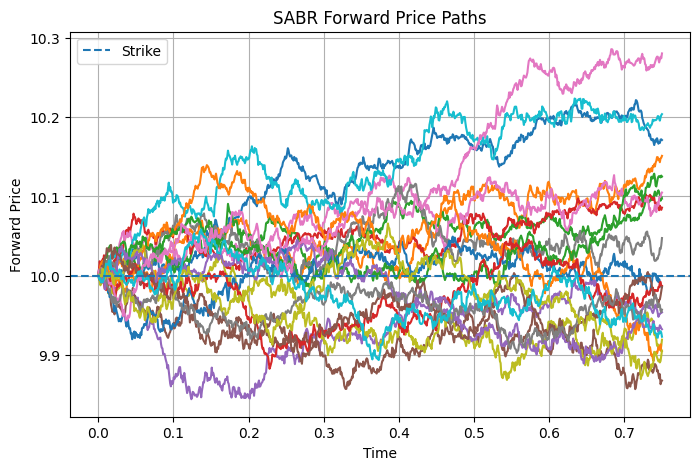

In [63]:
F_paths = sabr_paths(
    F0=F0,
    nu0=nu0,
    beta=beta,
    sigma=sigma,
    rho=rho,
    T=T,
    n_time=n_time,
    n_sim=20,
    seed=seed
)

time_grid = np.linspace(0, T, n_time + 1)

plt.figure(figsize=(8, 5))

for i in range(F_paths.shape[0]):
    plt.plot(time_grid, F_paths[i])

plt.axhline(X, linestyle="--", label="Strike")

plt.xlabel("Time")
plt.ylabel("Forward Price")
plt.title("SABR Forward Price Paths")
plt.legend()
plt.grid()
plt.show()

In [64]:
price_option_mc = sabr_option_price_mc(
    F0=F0,
    X=X,
    r=r,
    nu0=nu0,
    beta=beta,
    sigma=sigma,
    rho=rho,
    T=T,
    n_time=n_time,
    n_sim=n_sim_option,
    option_type=option_type,
    seed=seed
)

price_option_mcs = sabr_option_price_mcs(
    F0=F0,
    X=X,
    r=r,
    nu0=nu0,
    beta=beta,
    sigma=sigma,
    rho=rho,
    T=T,
    Nt=Nt,
    NF=NF,
    Nnu=Nnu,
    option_type=option_type
)

price_option_analytical = sabr_option_price_analytical(
    F0=F0,
    X=X,
    r=r,
    nu0=nu0,
    beta=beta,
    sigma=sigma,
    rho=rho,
    T=T,
    option_type=option_type
)

print(f"Analytical Option Price  : {price_option_analytical:.6f}")
print(f"Monte Carlo Option Price : {price_option_mc:.6f}")
print(f"MCS ADI Option Price      : {price_option_mcs:.6f}")

Analytical Option Price  : 0.047412
Monte Carlo Option Price : 0.047395
MCS ADI Option Price      : 0.047341


In [65]:
price_swaption_analytical = sabr_swaption_price_analytical(
    S0=S0, X=X, r=r,
    nu0=nu0, beta=beta, sigma=sigma, rho=rho, T=T,
    payment_times=payment_times,
    swaption_type=swaption_type
)

price_swaption_mc = sabr_swaption_price_mc(
    S0=S0, X=X, r=r,
    nu0=nu0, beta=beta, sigma=sigma, rho=rho, T=T,
    payment_times=payment_times,
    n_time=n_time, n_sim=n_sim_swaption,
    swaption_type=swaption_type, seed=seed
)

price_swaption_mcs = sabr_swaption_price_mcs(
    S0=S0, X=X, r=r,
    nu0=nu0, beta=beta, sigma=sigma, rho=rho, T=T,
    payment_times=payment_times,
    Nt=Nt, NS=NS, Nnu=Nnu,
    swaption_type=swaption_type
)

print(f"Analytical Swaption Price  : {price_swaption_analytical:.6f}")
print(f"Monte Carlo Swaption Price : {price_swaption_mc:.6f}")
print(f"MCS ADI Swaption Price      : {price_swaption_mcs:.6f}")

Analytical Swaption Price  : 0.152369
Monte Carlo Swaption Price : 0.153805
MCS ADI Swaption Price      : 0.152139
